<a href="https://colab.research.google.com/github/ligia-soares-ds/COVID-19-CNN-Pneumonia-Detector.ipynb/blob/main/COVID_19_CNN_Pneumonia_Detector.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import os
import glob        # lista os arquivos de imagem nas subpastas
import itertools   # gera todas as combinações do grid
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
import kagglehub
from sklearn.model_selection import train_test_split
from tensorflow.keras.preprocessing import image
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import (Input, Conv2D, MaxPooling2D, Flatten,
                                     GlobalAveragePooling2D, Dense, Dropout)
from tensorflow.keras.callbacks import EarlyStopping
from tensorflow.keras.optimizers import Adam, SGD

SEED = 42
tf.keras.utils.set_random_seed(SEED)   # reprodutibilidade: fixa Python, NumPy e TF

## Preparação dos dados

Utilizo o dataset *COVID-19 Xray Dataset (Train & Test Sets)*, com radiografias de tórax em duas classes: `PNEUMONIA` (casos de COVID-19) e `NORMAL`. O dataset já vem dividido em treino e teste, mas o desafio pede uma divisão fixa de 70% treino, 15% validação e 15% teste. Por isso, junto todas as imagens e refaço a divisão.

Faço a divisão de forma **estratificada**, para manter a mesma proporção de classes nos três conjuntos, e com **seed fixa**, para que ela seja reprodutível. O conjunto de teste fica separado e só será usado uma vez, no final, com o modelo escolhido.

In [ ]:
import kagglehub

# Download latest version
path = kagglehub.dataset_download("khoongweihao/covid19-xray-dataset-train-test-sets")

print("Path to dataset files:", path)

# --- Listar todas as imagens (das pastas train/ e test/ originais) ---
# recursive=True faz o glob entrar em todas as subpastas
arquivos = glob.glob(os.path.join(path, "**", "*.*"), recursive=True)
arquivos = [a for a in arquivos if a.lower().endswith((".png", ".jpg", ".jpeg"))]

# --- Montar o DataFrame: o rótulo é o nome da pasta onde a imagem está ---
df = pd.DataFrame({
    "filepath": arquivos,
    "label": [os.path.basename(os.path.dirname(a)) for a in arquivos],
})
print("\nTotal de imagens:", len(df))
print(df["label"].value_counts())

# --- Divisão estratificada: 70% treino / 30% resto ---
df_tr, df_tmp = train_test_split(
    df, test_size=0.30, stratify=df["label"], random_state=SEED
)
# --- O resto é dividido ao meio: 15% validação / 15% teste ---
df_va, df_te = train_test_split(
    df_tmp, test_size=0.50, stratify=df_tmp["label"], random_state=SEED
)

# --- Conferir tamanhos e proporções de cada conjunto ---
print()
for nome, d in [("Treino", df_tr), ("Validação", df_va), ("Teste", df_te)]:
    print(f"{nome:10s} n={len(d):3d}  {d['label'].value_counts().to_dict()}")

Using Colab cache for faster access to the 'covid19-xray-dataset-train-test-sets' dataset.
Path to dataset files: /kaggle/input/covid19-xray-dataset-train-test-sets

Total de imagens: 188
label
PNEUMONIA    94
NORMAL       94
Name: count, dtype: int64

Treino     n=131  {'PNEUMONIA': 66, 'NORMAL': 65}
Validação  n= 28  {'NORMAL': 14, 'PNEUMONIA': 14}
Teste      n= 29  {'NORMAL': 15, 'PNEUMONIA': 14}


Found 131 validated image filenames belonging to 2 classes.
Found 28 validated image filenames belonging to 2 classes.
Found 29 validated image filenames belonging to 2 classes.

Mapeamento das classes: {'NORMAL': 0, 'PNEUMONIA': 1}
Shape do lote de imagens: (16, 128, 128, 1)
Shape do lote de rótulos: (16,)
Mín e máx dos pixels: 0.0 1.0


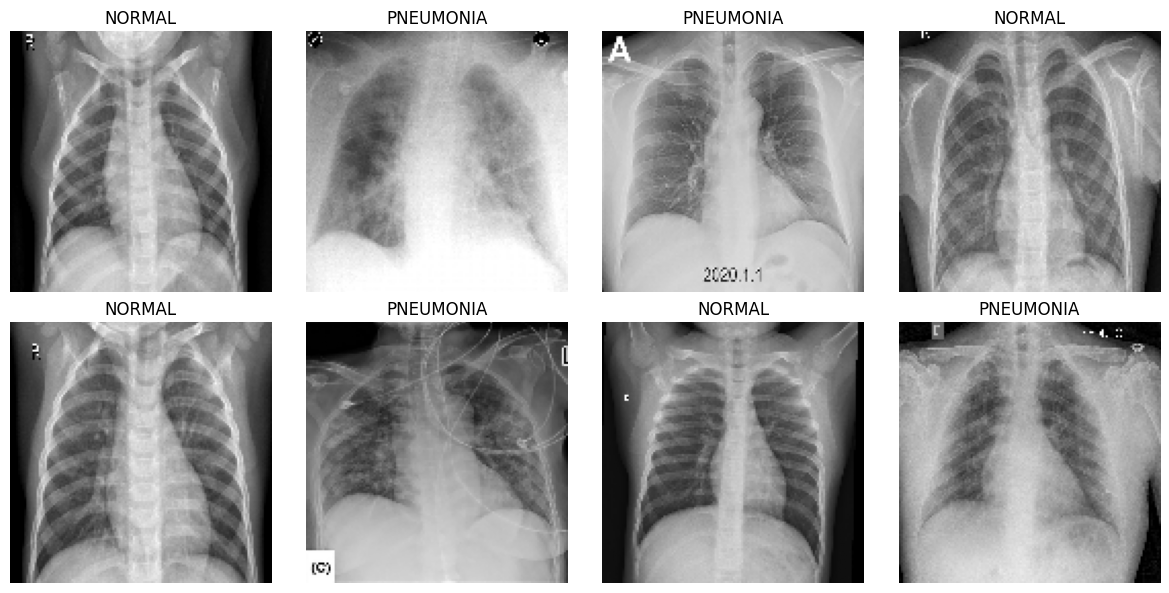

In [ ]:
IMG_SIZE = 128

def criar_geradores(batch_size):
    """Cria os geradores de treino, validação e teste para um dado batch size."""
    gen = ImageDataGenerator(rescale=1./255)   # mesma normalização para todos

    comum = dict(
        x_col="filepath",
        y_col="label",
        target_size=(IMG_SIZE, IMG_SIZE),
        color_mode="grayscale",   # 1 canal → entrada (128, 128, 1)
        class_mode="binary",      # rótulo 0 ou 1
        batch_size=batch_size,
    )

    train_gen = gen.flow_from_dataframe(df_tr, shuffle=True, seed=SEED, **comum)
    val_gen   = gen.flow_from_dataframe(df_va, shuffle=False, **comum)
    test_gen  = gen.flow_from_dataframe(df_te, shuffle=False, **comum)
    return train_gen, val_gen, test_gen


# --- Teste de sanidade com um batch size qualquer ---
train_gen, val_gen, test_gen = criar_geradores(batch_size=16)

print("\nMapeamento das classes:", train_gen.class_indices)

x_batch, y_batch = next(train_gen)
print("Shape do lote de imagens:", x_batch.shape)   # esperado: (16, 128, 128, 1)
print("Shape do lote de rótulos:", y_batch.shape)   # esperado: (16,)
print("Mín e máx dos pixels:", x_batch.min(), x_batch.max())   # esperado: entre 0 e 1

# --- Olhar algumas imagens com seus rótulos ---
nomes = {v: k for k, v in train_gen.class_indices.items()}
fig, axes = plt.subplots(2, 4, figsize=(12, 6))
for ax, img, lab in zip(axes.flat, x_batch, y_batch):
    ax.imshow(img.squeeze(), cmap="gray")
    ax.set_title(nomes[int(lab)])
    ax.axis("off")
plt.tight_layout()
plt.show()

## Arquitetura da CNN

Defino uma função que constrói a CNN a partir dos hiperparâmetros, para que cada combinação do grid gere um modelo novo, treinado do zero.

- **Blocos convolucionais**: cada bloco tem uma camada `Conv2D` (extrai padrões locais, como bordas e texturas) seguida de `MaxPooling2D` (reduz a resolução pela metade e mantém as ativações mais fortes). O número de filtros aumenta com a profundidade: as primeiras camadas detectam padrões simples, e as seguintes combinam esses padrões em estruturas mais complexas.
- **`GlobalAveragePooling2D` em vez de `Flatten`**: tiro a média de cada mapa de ativação, gerando um valor por filtro. Isso reduz drasticamente o número de parâmetros, o que é importante com apenas 131 imagens de treino. Com `Flatten`, a primeira camada densa poderia ter milhões de parâmetros e decorar o conjunto de treino.
- **Dropout**: durante o treino, desligo aleatoriamente uma fração dos neurônios, para que a rede não dependa de poucos neurônios específicos. É uma forma de regularização.
- **Saída**: um neurônio com sigmoide, que dá a probabilidade de a imagem ser da classe `PNEUMONIA`, com perda `binary_crossentropy`.

In [ ]:
def criar_modelo(filtros, dropout, otimizador, lr):
    """
    filtros    : tupla com o nº de filtros de cada bloco conv, ex.: (16, 32) → 2 blocos
    dropout    : fração de neurônios desligados (0.0 = sem dropout)
    otimizador : "adam" ou "sgd"
    lr         : learning rate
    """
    model = Sequential()
    model.add(Input(shape=(IMG_SIZE, IMG_SIZE, 1)))   # 1 canal: escala de cinza

    # Um bloco Conv + Pool para cada valor da tupla de filtros
    for f in filtros:
        model.add(Conv2D(f, (3, 3), activation="relu", padding="same"))
        model.add(MaxPooling2D((2, 2)))

    model.add(GlobalAveragePooling2D())   # (altura, largura, filtros) → (filtros,)
    model.add(Dense(32, activation="relu"))
    model.add(Dropout(dropout))           # Dropout(0.0) não faz nada: equivale a "sem dropout"
    model.add(Dense(1, activation="sigmoid"))

    # Otimizador escolhido pelo nome
    if otimizador == "adam":
        opt = Adam(learning_rate=lr)
    elif otimizador == "sgd":
        opt = SGD(learning_rate=lr, momentum=0.9)   # momentum: "inércia" que suaviza o caminho
    else:
        raise ValueError(f"Otimizador desconhecido: {otimizador}")

    model.compile(optimizer=opt, loss="binary_crossentropy", metrics=["accuracy"])
    return model


# --- Teste de sanidade: montar dois modelos e comparar o tamanho ---
m_pequeno = criar_modelo(filtros=(16, 32), dropout=0.3, otimizador="adam", lr=1e-3)
m_maior   = criar_modelo(filtros=(16, 32, 64), dropout=0.3, otimizador="adam", lr=1e-3)
m_pequeno.summary()
m_maior.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 128, 128, 16)   │           160 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 64, 64, 16)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 64, 64, 32)     │         4,640 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 32, 32, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 32)             │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 32)             │         1,056 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 5,889 (23.00 KB)

 Trainable params: 5,889 (23.00 KB)

 Non-trainable params: 0 (0.00 B)

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_2 (Conv2D)               │ (None, 128, 128, 16)   │           160 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 64, 64, 16)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 64, 64, 32)     │         4,640 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 32, 32, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (None, 32, 32, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_4 (MaxPooling2D)  │ (None, 16, 16, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_1      │ (None, 64)             │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 25,409 (99.25 KB)

 Trainable params: 25,409 (99.25 KB)

 Non-trainable params: 0 (0.00 B)

   # Otimização de uma CNN com Grid Search: classificação de radiografias de tórax

   Neste notebook, busco a combinação de hiperparâmetros de uma CNN que apresenta **melhor generalização**, e não apenas melhor desempenho no treino. Uso uma divisão fixa de 70% treino, 15% validação e 15% teste: seleciono o modelo apenas com treino e validação, e uso o teste uma única vez, ao final.

## Grid search

Testo 32 combinações de hiperparâmetros: arquitetura (2 ou 3 blocos convolucionais), dropout (0 ou 0,5), batch size (8 ou 16) e otimizador com learning rate. Trato otimizador e learning rate como pares, porque o SGD costuma precisar de learning rates maiores que o Adam; cruzar todos os valores com todos poderia prejudicar um dos otimizadores injustamente.

Para que a comparação seja justa, todas as configurações seguem o mesmo protocolo:
- mesma seed no início de cada treino;
- no máximo 40 épocas, com early stopping monitorando a `val_loss` (paciência de 6 épocas), restaurando os pesos da melhor época;
- métricas de treino recalculadas com `evaluate` ao final, porque durante o treino o dropout está ativo e distorce a acurácia de treino.

**Critério de seleção, definido antes de ver os resultados:** escolho a configuração com menor `val_loss`. O conjunto de teste não é usado nesta etapa.

In [ ]:
import time

# --- Definição do grid ---
grid = {
    "filtros":    [(16, 32), (16, 32, 64)],
    "dropout":    [0.0, 0.5],
    "batch_size": [8, 16],
    "opt_lr":     [("adam", 1e-3), ("adam", 1e-4), ("sgd", 1e-2), ("sgd", 1e-3)],
}
# itertools.product gera todas as combinações possíveis
combinacoes = list(itertools.product(*grid.values()))
print(f"Total de configurações: {len(combinacoes)}")

MAX_EPOCHS = 40
resultados = []    # uma linha por configuração
historicos = {}    # curvas de cada configuração, para os gráficos depois

for i, (filtros, dropout, batch_size, (opt, lr)) in enumerate(combinacoes, start=1):
    inicio = time.time()
    tf.keras.utils.set_random_seed(SEED)   # mesma seed para TODAS as configurações

    train_gen, val_gen, _ = criar_geradores(batch_size)   # o "_" ignora o teste de propósito
    model = criar_modelo(filtros, dropout, opt, lr)

    es = EarlyStopping(monitor="val_loss", patience=6, restore_best_weights=True)
    hist = model.fit(train_gen, validation_data=val_gen, epochs=MAX_EPOCHS,
                     callbacks=[es], verbose=0)   # verbose=0: sem barra de progresso

    # Métricas "limpas" (sem dropout), com os pesos da melhor época
    train_loss, train_acc = model.evaluate(train_gen, verbose=0)
    val_loss, val_acc = model.evaluate(val_gen, verbose=0)

    resultados.append({
        "id": i, "filtros": str(filtros), "dropout": dropout,
        "batch_size": batch_size, "otimizador": opt, "lr": lr,
        "melhor_epoca": int(np.argmin(hist.history["val_loss"])) + 1,
        "train_loss": train_loss, "train_acc": train_acc,
        "val_loss": val_loss, "val_acc": val_acc,
        "gap_acc": train_acc - val_acc,   # quanto maior, mais sinal de overfitting
        "tempo_s": round(time.time() - inicio, 1),
    })
    historicos[i] = hist.history

    print(f"[{i:2d}/{len(combinacoes)}] filtros={filtros} drop={dropout} bs={batch_size} "
          f"{opt} lr={lr:g} → val_loss={val_loss:.3f} val_acc={val_acc:.3f} "
          f"({resultados[-1]['tempo_s']}s)")

# Salvo tudo num CSV, para não perder os resultados se o Colab desconectar
df_res = pd.DataFrame(resultados)
df_res.to_csv("resultados_grid.csv", index=False)
print("\nResultados salvos em resultados_grid.csv")

Total de configurações: 32
Found 131 validated image filenames belonging to 2 classes.
Found 28 validated image filenames belonging to 2 classes.
Found 29 validated image filenames belonging to 2 classes.
[ 1/32] filtros=(16, 32) drop=0.0 bs=8 adam lr=0.001 → val_loss=0.590 val_acc=0.821 (143.7s)
Found 131 validated image filenames belonging to 2 classes.
Found 28 validated image filenames belonging to 2 classes.
Found 29 validated image filenames belonging to 2 classes.
[ 2/32] filtros=(16, 32) drop=0.0 bs=8 adam lr=0.0001 → val_loss=0.665 val_acc=0.750 (218.4s)
Found 131 validated image filenames belonging to 2 classes.
Found 28 validated image filenames belonging to 2 classes.
Found 29 validated image filenames belonging to 2 classes.
[ 3/32] filtros=(16, 32) drop=0.0 bs=8 sgd lr=0.01 → val_loss=0.622 val_acc=0.714 (222.1s)
Found 131 validated image filenames belonging to 2 classes.
Found 28 validated image filenames belonging to 2 classes.
Found 29 validated image filenames belongi

## Análise dos resultados do grid

Ordeno as 32 configurações pela `val_loss`, o critério que defini antes do treino, e olho também o gap entre a acurácia de treino e a de validação, que indica overfitting.

Também calculo a `val_loss` média para cada valor de cada hiperparâmetro. Isso me mostra quais escolhas tiveram mais impacto na generalização, sem depender de uma única configuração. Com apenas 28 imagens de validação, cada acerto vale cerca de 3,6 pontos percentuais, então diferenças pequenas entre as melhores configurações podem ser ruído.

Várias configurações terminaram com `val_loss ≈ 0,69` e `val_acc = 0,50`. Esse valor é −ln(0,5), a perda de um modelo que atribui 50% de probabilidade a todas as imagens: essas configurações não aprenderam, ficaram no nível do acaso.

Top 10 configurações (ordenadas por val_loss):


,id,filtros,dropout,batch_size,otimizador,lr,melhor_epoca,train_loss,train_acc,val_loss,val_acc,gap_acc
0,29,"(16, 32, 64)",0.5,16,adam,0.001,32,0.169,0.908,0.460,0.821,0.087
1,25,"(16, 32, 64)",0.5,8,adam,0.001,24,0.178,0.901,0.514,0.857,0.044
2,18,"(16, 32, 64)",0.0,8,adam,0.000,40,0.394,0.840,0.515,0.821,0.018
3,9,"(16, 32)",0.5,8,adam,0.001,40,0.347,0.832,0.518,0.786,0.046
4,26,"(16, 32, 64)",0.5,8,adam,0.000,39,0.504,0.840,0.573,0.786,0.054
5,5,"(16, 32)",0.0,16,adam,0.001,21,0.437,0.817,0.579,0.786,0.031
6,13,"(16, 32)",0.5,16,adam,0.001,36,0.505,0.771,0.581,0.786,-0.015
7,21,"(16, 32, 64)",0.0,16,adam,0.001,12,0.412,0.847,0.586,0.714,0.133
8,1,"(16, 32)",0.0,8,adam,0.001,18,0.400,0.802,0.590,0.821,-0.020
9,17,"(16, 32, 64)",0.0,8,adam,0.001,7,0.392,0.817,0.596,0.786,0.031



Melhor configuração:
id                        29
filtros         (16, 32, 64)
dropout                  0.5
batch_size                16
otimizador              adam
lr                     0.001
melhor_epoca              32
train_loss          0.169192
train_acc           0.908397
val_loss            0.459941
val_acc             0.821429
gap_acc             0.086968
Name: 0, dtype: object

Configurações no nível do acaso (val_loss > 0,67): 16 de 32

val_loss média por valor de cada hiperparâmetro:

filtros:
               mean    std
filtros                   
(16, 32)      0.653  0.056
(16, 32, 64)  0.622  0.076

dropout:
          mean    std
dropout              
0.0      0.637  0.054
0.5      0.638  0.080

batch_size:
             mean    std
batch_size              
8           0.629  0.069
16          0.646  0.066

otimizador:
             mean    std
otimizador              
adam        0.594  0.069
sgd         0.681  0.022

lr:
         mean    std
lr                  
0.0001 

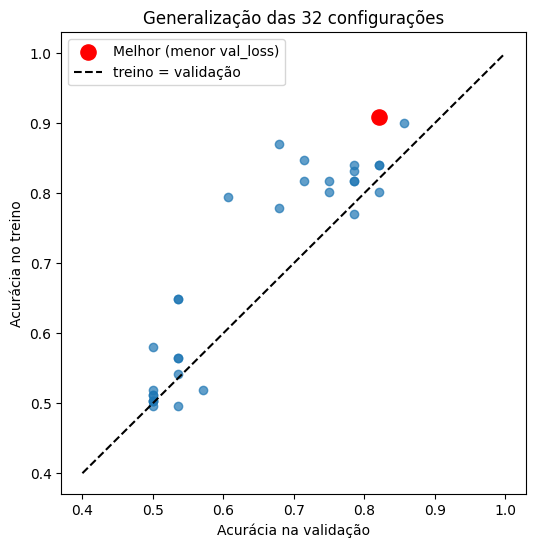

In [ ]:
colunas = ["id", "filtros", "dropout", "batch_size", "otimizador", "lr", "melhor_epoca",
           "train_loss", "train_acc", "val_loss", "val_acc", "gap_acc"]

# --- Ranking pelo critério definido antes: menor val_loss ---
ranking = df_res.sort_values("val_loss").reset_index(drop=True)
print("Top 10 configurações (ordenadas por val_loss):")
display(ranking[colunas].head(10).round(3))

melhor = ranking.iloc[0]
print("\nMelhor configuração:")
print(melhor[colunas])

# --- Quantas configurações não aprenderam (ficaram no acaso)? ---
nao_aprendeu = df_res[df_res["val_loss"] > 0.67]
print(f"\nConfigurações no nível do acaso (val_loss > 0,67): {len(nao_aprendeu)} de {len(df_res)}")

# --- Efeito médio de cada hiperparâmetro na val_loss ---
print("\nval_loss média por valor de cada hiperparâmetro:")
for hp in ["filtros", "dropout", "batch_size", "otimizador", "lr"]:
    print(f"\n{hp}:")
    print(df_res.groupby(hp)["val_loss"].agg(["mean", "std"]).round(3))

# --- Treino vs validação: quem está acima da diagonal "decorou" ---
fig, ax = plt.subplots(figsize=(6, 6))
ax.scatter(df_res["val_acc"], df_res["train_acc"], alpha=0.7)
ax.scatter(melhor["val_acc"], melhor["train_acc"], color="red", s=120,
           label="Melhor (menor val_loss)")
ax.plot([0.4, 1.0], [0.4, 1.0], "k--", label="treino = validação")
ax.set_xlabel("Acurácia na validação")
ax.set_ylabel("Acurácia no treino")
ax.set_title("Generalização das 32 configurações")
ax.legend()
plt.show()

## Avaliação final do melhor modelo

Como o grid guardou apenas as métricas, retreino a melhor configuração com a mesma seed e o mesmo protocolo. Confiro se a `val_loss` do retreino fica próxima da obtida no grid; pequenas diferenças podem vir do não determinismo da GPU.

Só agora uso o conjunto de teste, uma única vez. Comparo loss e acurácia nos três conjuntos, apresento as curvas de aprendizado e a matriz de confusão no teste, com sensibilidade e especificidade. Como o teste tem apenas 29 imagens, calculo também o intervalo de confiança de 95% (Wilson) da acurácia, para deixar explícita a incerteza da estimativa.

Retreinando: filtros=(16, 32, 64), dropout=0.5, batch=16, adam, lr=0.001
Found 131 validated image filenames belonging to 2 classes.
Found 28 validated image filenames belonging to 2 classes.
Found 29 validated image filenames belonging to 2 classes.


,Conjunto,n,Loss,Acurácia
0,Treino,131,0.169,0.908
1,Validação,28,0.460,0.821
2,Teste,29,0.359,0.828


val_loss no grid: 0.460 | no retreino: 0.460


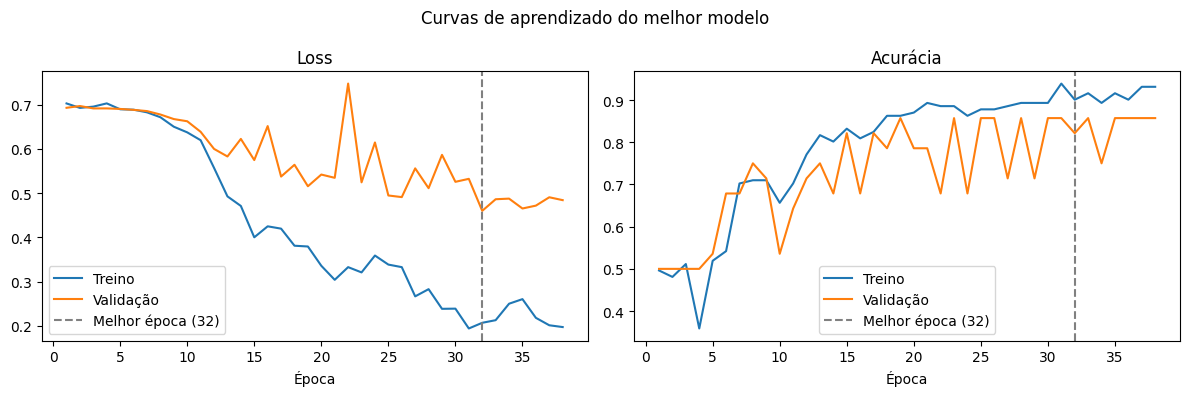

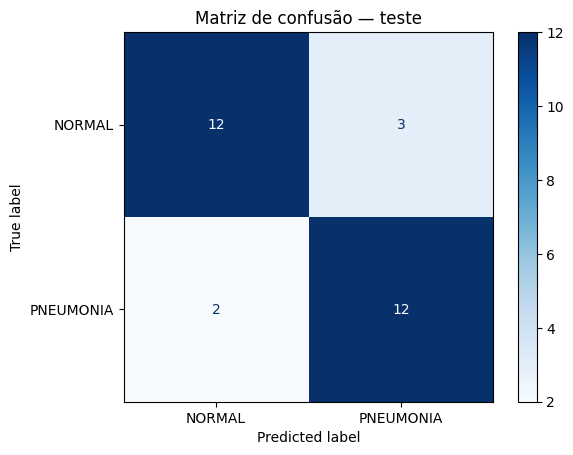

Sensibilidade (acerta PNEUMONIA): 0.857  (12/14)
Especificidade (acerta NORMAL):   0.800  (12/15)
Acurácia no teste: 24/29 = 0.828  (IC 95%: 0.655 a 0.924)


In [ ]:
import ast
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
from statsmodels.stats.proportion import proportion_confint

# --- 1. Recuperar os hiperparâmetros do vencedor ---
# (filtros foi salvo como texto, ex.: "(16, 32, 64)"; literal_eval converte de volta para tupla)
best_filtros = ast.literal_eval(melhor["filtros"])
best_dropout = float(melhor["dropout"])
best_bs      = int(melhor["batch_size"])
best_opt     = melhor["otimizador"]
best_lr      = float(melhor["lr"])
print(f"Retreinando: filtros={best_filtros}, dropout={best_dropout}, "
      f"batch={best_bs}, {best_opt}, lr={best_lr:g}")

# --- 2. Retreinar com o mesmo protocolo do grid ---
tf.keras.utils.set_random_seed(SEED)
train_gen, val_gen, test_gen = criar_geradores(best_bs)
best_model = criar_modelo(best_filtros, best_dropout, best_opt, best_lr)
es = EarlyStopping(monitor="val_loss", patience=6, restore_best_weights=True)
hist_best = best_model.fit(train_gen, validation_data=val_gen, epochs=MAX_EPOCHS,
                           callbacks=[es], verbose=0)

# --- 3. Loss e acurácia nos três conjuntos (o teste entra AQUI, pela primeira vez) ---
tabela = []
for nome, g in [("Treino", train_gen), ("Validação", val_gen), ("Teste", test_gen)]:
    loss, acc = best_model.evaluate(g, verbose=0)
    tabela.append({"Conjunto": nome, "n": g.n, "Loss": loss, "Acurácia": acc})
df_final = pd.DataFrame(tabela)
display(df_final.round(3))
print(f"val_loss no grid: {melhor['val_loss']:.3f} | no retreino: {df_final.loc[1, 'Loss']:.3f}")

# --- 4. Curvas de aprendizado ---
ep_best = int(np.argmin(hist_best.history["val_loss"])) + 1   # época restaurada pelo early stopping
epocas = range(1, len(hist_best.history["loss"]) + 1)
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4))
for ax, metrica, titulo in [(ax1, "loss", "Loss"), (ax2, "accuracy", "Acurácia")]:
    ax.plot(epocas, hist_best.history[metrica], label="Treino")
    ax.plot(epocas, hist_best.history["val_" + metrica], label="Validação")
    ax.axvline(ep_best, color="gray", ls="--", label=f"Melhor época ({ep_best})")
    ax.set_xlabel("Época"); ax.set_title(titulo); ax.legend()
plt.suptitle("Curvas de aprendizado do melhor modelo")
plt.tight_layout(); plt.show()

# --- 5. Matriz de confusão no teste ---
# test_gen tem shuffle=False, então test_gen.classes está na mesma ordem das predições
y_true = test_gen.classes
y_prob = best_model.predict(test_gen, verbose=0).ravel()
y_pred = (y_prob >= 0.5).astype(int)

cm = confusion_matrix(y_true, y_pred)
nomes_classes = list(test_gen.class_indices.keys())   # ['NORMAL', 'PNEUMONIA']
ConfusionMatrixDisplay(cm, display_labels=nomes_classes).plot(cmap="Blues")
plt.title("Matriz de confusão — teste"); plt.show()

tn, fp, fn, tp = cm.ravel()
print(f"Sensibilidade (acerta PNEUMONIA): {tp / (tp + fn):.3f}  ({tp}/{tp + fn})")
print(f"Especificidade (acerta NORMAL):   {tn / (tn + fp):.3f}  ({tn}/{tn + fp})")

# --- 6. Intervalo de confiança da acurácia no teste ---
acertos = tp + tn
li, ls = proportion_confint(acertos, len(y_true), alpha=0.05, method="wilson")
print(f"Acurácia no teste: {acertos}/{len(y_true)} = {acertos / len(y_true):.3f}  "
      f"(IC 95%: {li:.3f} a {ls:.3f})")

## Visualizações dos resultados

Para facilitar a leitura dos resultados, resumo as principais análises em quatro figuras. Cada uma também é salva como PNG, para eu poder usar em slides.

### Visão geral do grid

Neste mapa de calor, cada célula é uma das 32 configurações, e a cor indica a `val_loss` (quanto mais escuro, menor a perda). As linhas são os pares de otimizador e learning rate, e as colunas combinam arquitetura, dropout e batch size. Assim consigo ver de uma vez quais escolhas levaram aos melhores resultados.

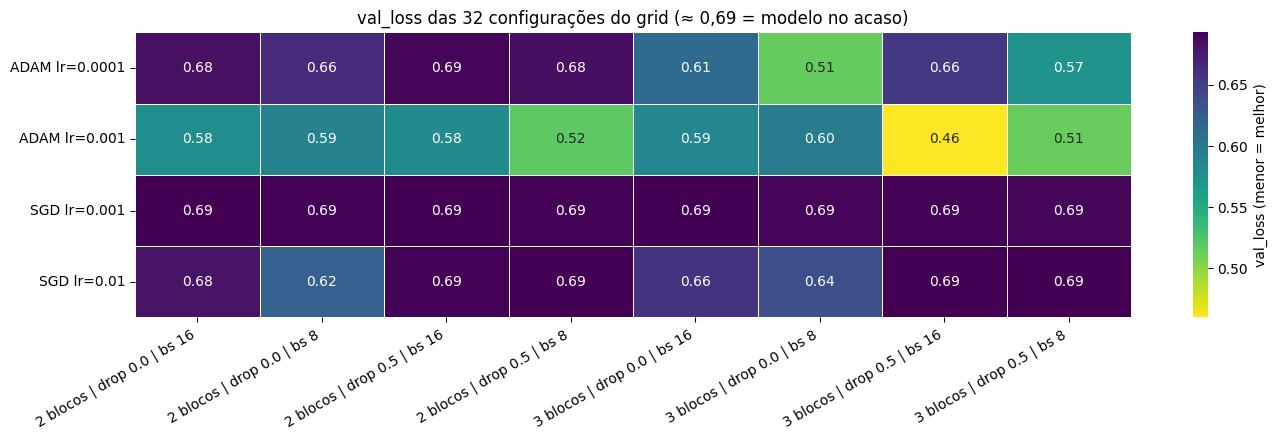

In [ ]:
import ast
import seaborn as sns

viz = df_res.copy()
viz["blocos"] = viz["filtros"].apply(lambda s: len(ast.literal_eval(s)))   # "(16, 32)" → 2
viz["opt_lr"] = viz["otimizador"].str.upper() + " lr=" + viz["lr"].map(lambda x: f"{x:g}")
viz["config"] = (viz["blocos"].astype(str) + " blocos | drop " + viz["dropout"].astype(str)
                 + " | bs " + viz["batch_size"].astype(str))

mapa = viz.pivot(index="opt_lr", columns="config", values="val_loss")

fig, ax = plt.subplots(figsize=(14, 4.5))
sns.heatmap(mapa, annot=True, fmt=".2f", cmap="viridis_r", linewidths=0.5,
            cbar_kws={"label": "val_loss (menor = melhor)"}, ax=ax)
ax.set_title("val_loss das 32 configurações do grid (≈ 0,69 = modelo no acaso)")
ax.set_xlabel(""); ax.set_ylabel("")
plt.xticks(rotation=30, ha="right")
plt.tight_layout()
plt.savefig("fig1_heatmap_grid.png", dpi=150, bbox_inches="tight")
plt.show()

### Efeito de cada hiperparâmetro

Para cada hiperparâmetro, calculo a `val_loss` média entre todas as configurações que usaram cada valor, com o desvio padrão. A linha tracejada marca 0,693, a perda de um modelo que responde 50% para todas as imagens. Analiso otimizador e learning rate juntos, porque eles foram testados em pares.

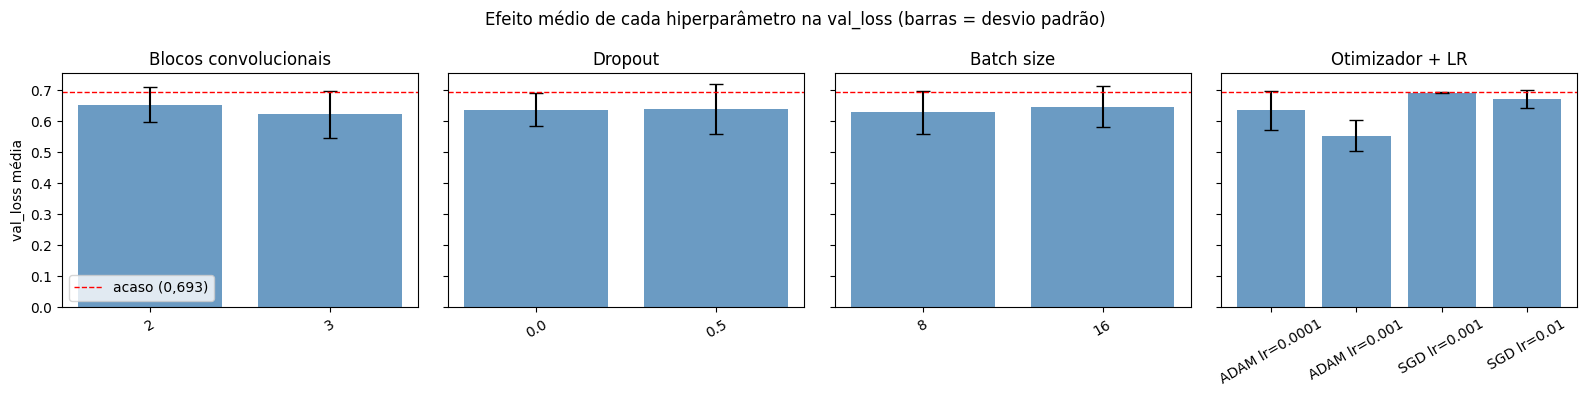

In [ ]:
fatores = [("blocos", "Blocos convolucionais"), ("dropout", "Dropout"),
           ("batch_size", "Batch size"), ("opt_lr", "Otimizador + LR")]

fig, axes = plt.subplots(1, 4, figsize=(16, 4), sharey=True)
for ax, (col, titulo) in zip(axes, fatores):
    resumo = viz.groupby(col)["val_loss"].agg(["mean", "std"])
    ax.bar(resumo.index.astype(str), resumo["mean"], yerr=resumo["std"],
           capsize=5, color="steelblue", alpha=0.8)
    ax.axhline(0.693, color="red", ls="--", lw=1, label="acaso (0,693)")
    ax.set_title(titulo)
    ax.tick_params(axis="x", rotation=30)
axes[0].set_ylabel("val_loss média")
axes[0].legend()
plt.suptitle("Efeito médio de cada hiperparâmetro na val_loss (barras = desvio padrão)")
plt.tight_layout()
plt.savefig("fig2_efeito_hiperparametros.png", dpi=150, bbox_inches="tight")
plt.show()

### Desempenho do melhor modelo nos três conjuntos

Comparo loss e acurácia no treino, na validação e no teste. Valores semelhantes nos três conjuntos indicam que o modelo generaliza, em vez de ter decorado o treino. Na acurácia do teste, a barra de erro mostra o intervalo de confiança de 95% (Wilson), que é largo porque o teste tem apenas 29 imagens.

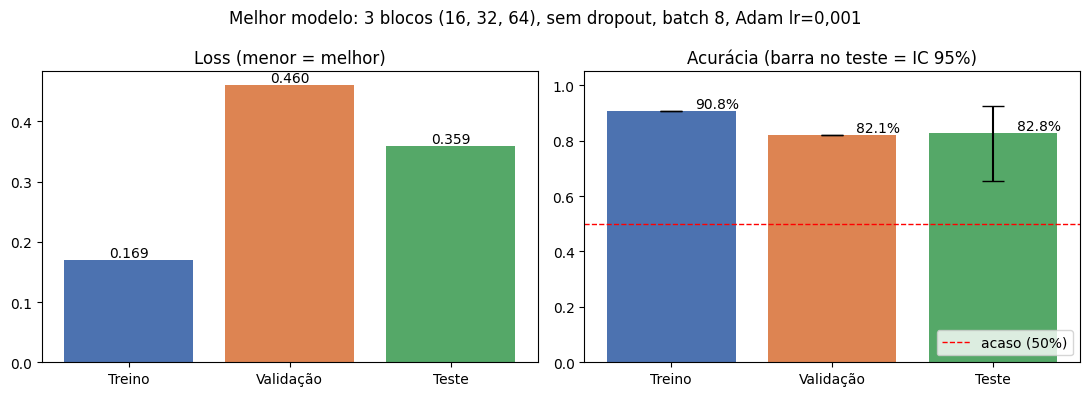

In [ ]:
cores = ["#4C72B0", "#DD8452", "#55A868"]   # treino, validação, teste
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 4))

# Loss
ax1.bar(df_final["Conjunto"], df_final["Loss"], color=cores)
for i, v in enumerate(df_final["Loss"]):
    ax1.text(i, v + 0.005, f"{v:.3f}", ha="center")
ax1.set_title("Loss (menor = melhor)")

# Acurácia, com IC 95% só no teste
acc = df_final["Acurácia"].values
erro_inf = [0, 0, acc[2] - li]
erro_sup = [0, 0, ls - acc[2]]
ax2.bar(df_final["Conjunto"], acc, color=cores, yerr=[erro_inf, erro_sup], capsize=8)
for i, v in enumerate(acc):
    ax2.text(i + 0.15, v + 0.01, f"{v:.1%}", ha="left")
ax2.axhline(0.5, color="red", ls="--", lw=1, label="acaso (50%)")
ax2.set_ylim(0, 1.05)
ax2.set_title("Acurácia (barra no teste = IC 95%)")
ax2.legend(loc="lower right")

plt.suptitle("Melhor modelo: 3 blocos (16, 32, 64), sem dropout, batch 8, Adam lr=0,001")
plt.tight_layout()
plt.savefig("fig3_treino_val_teste.png", dpi=150, bbox_inches="tight")
plt.show()

### Predições no conjunto de teste

Mostro as 29 imagens do teste com o rótulo real, o rótulo previsto e a probabilidade atribuída à classe PNEUMONIA. Os acertos aparecem em verde e os erros em vermelho. Isso me permite olhar diretamente para o caso em que o modelo errou e checar se há algo na imagem que explique o erro.

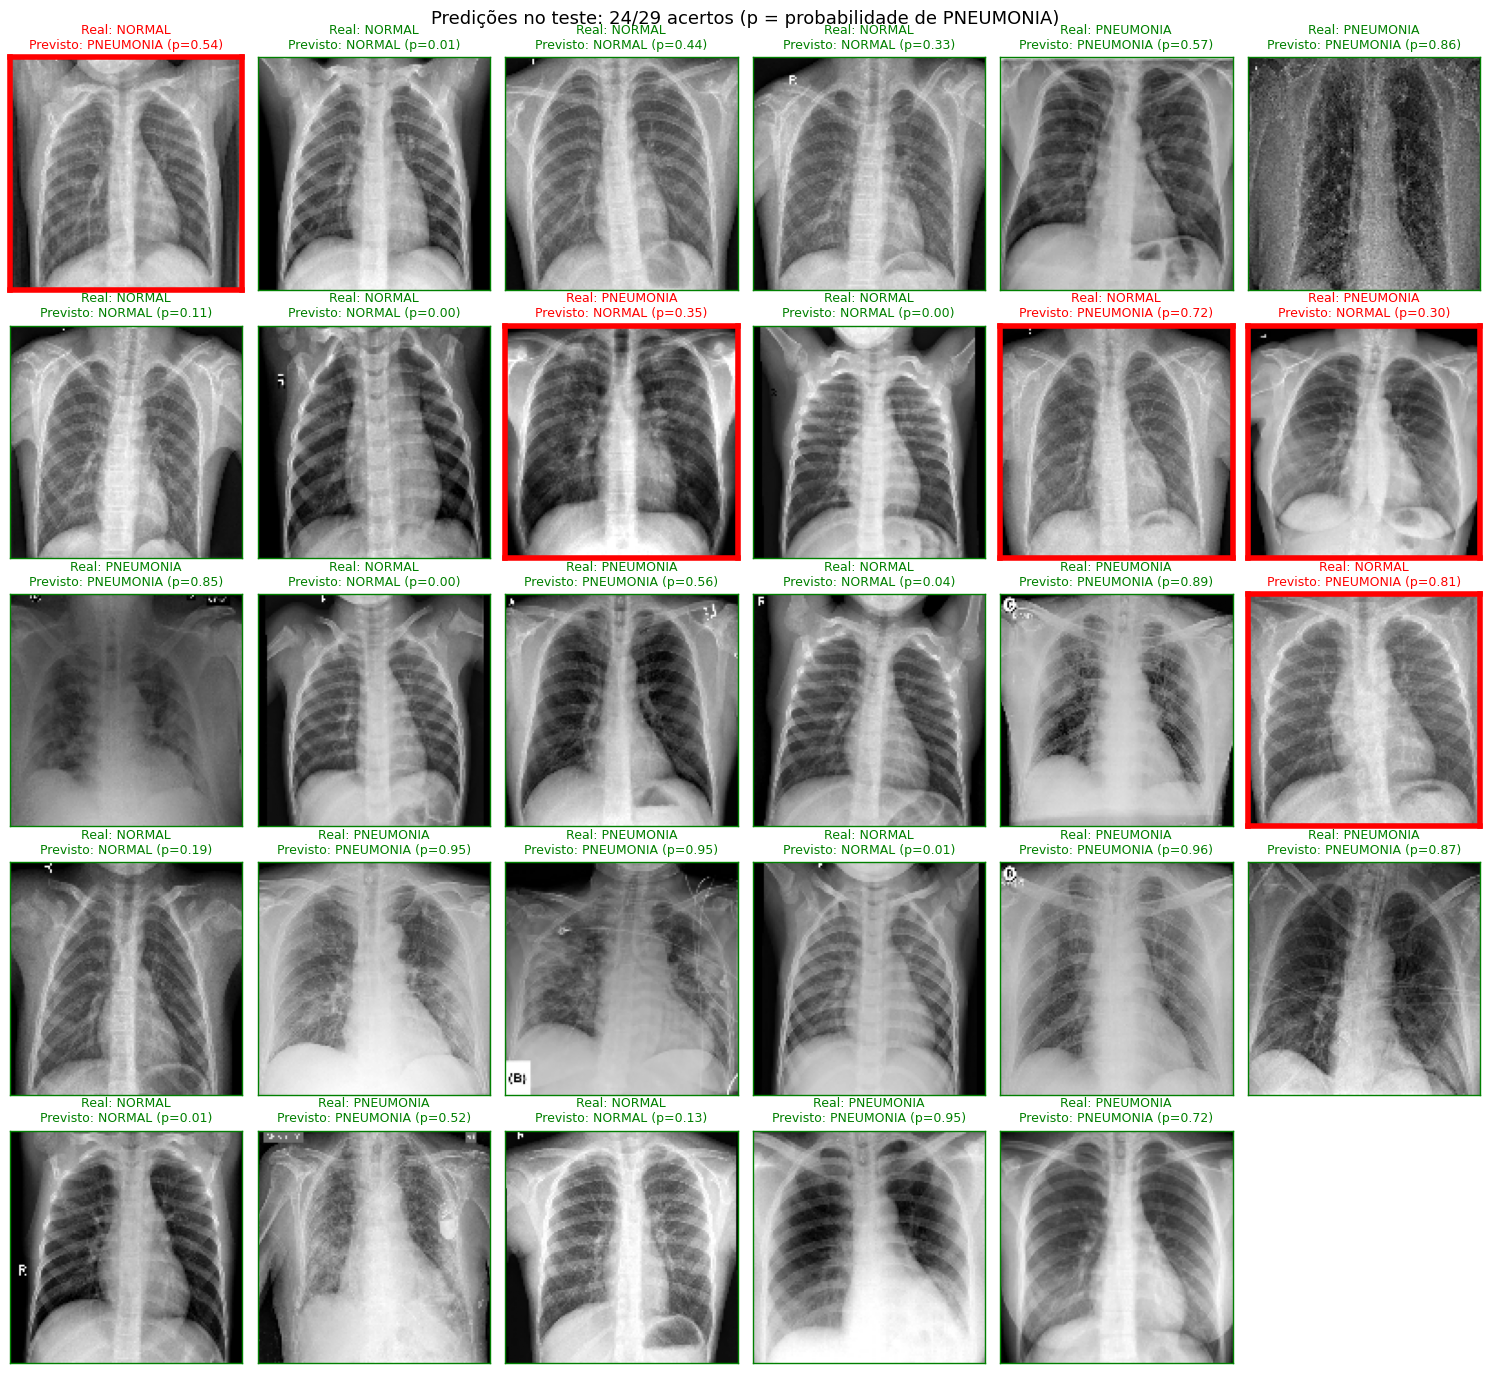

In [ ]:
# Junta todas as imagens do teste numa única matriz
# (test_gen tem shuffle=False, então a ordem bate com y_true e y_prob da Etapa 7)
x_test = np.concatenate([test_gen[i][0] for i in range(len(test_gen))])
nomes = {v: k for k, v in test_gen.class_indices.items()}   # 0 → NORMAL, 1 → PNEUMONIA

n_cols = 6
n_rows = int(np.ceil(len(x_test) / n_cols))
fig, axes = plt.subplots(n_rows, n_cols, figsize=(15, 2.8 * n_rows))

for ax, img, real, pred, prob in zip(axes.flat, x_test, y_true, y_pred, y_prob):
    acertou = real == pred
    ax.imshow(img.squeeze(), cmap="gray")
    ax.set_title(f"Real: {nomes[real]}\nPrevisto: {nomes[pred]} (p={prob:.2f})",
                 fontsize=9, color="green" if acertou else "red")
    for borda in ax.spines.values():          # moldura vermelha nos erros
        borda.set_edgecolor("green" if acertou else "red")
        borda.set_linewidth(1 if acertou else 4)
    ax.set_xticks([]); ax.set_yticks([])

for ax in axes.flat[len(x_test):]:            # esconde os quadros vazios do fim
    ax.axis("off")

plt.suptitle(f"Predições no teste: {acertos}/{len(y_true)} acertos "
             "(p = probabilidade de PNEUMONIA)", fontsize=13)
plt.tight_layout()
plt.savefig("fig4_predicoes_teste.png", dpi=150, bbox_inches="tight")
plt.show()

## Análises complementares

### Curva ROC e confiança do modelo

A acurácia depende do limiar de 0,5. A curva ROC mostra a sensibilidade e a taxa de falsos positivos para todos os limiares possíveis, e a área sob a curva (AUC) resume a capacidade de separar as classes: 0,5 é o acaso e 1,0 é a separação perfeita. O histograma mostra a probabilidade de PNEUMONIA que o modelo atribuiu a cada imagem do teste, separada pela classe real. Quanto mais afastados os dois grupos estiverem do limiar, mais confiante o modelo está. Com apenas 29 imagens, a AUC também tem incerteza alta.

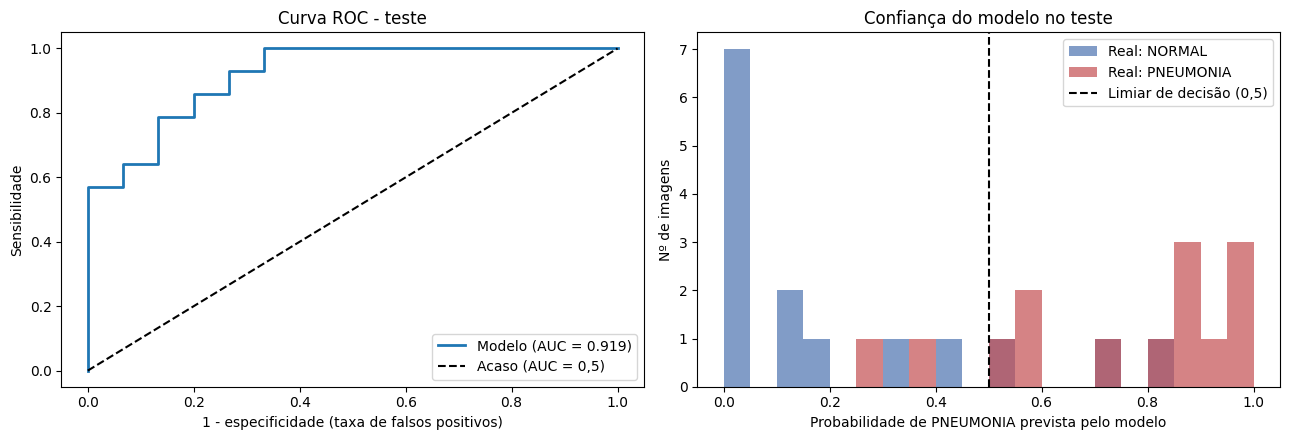

AUC no teste: 0.919


In [ ]:
from sklearn.metrics import roc_curve, roc_auc_score

y_true_arr = np.array(y_true)
fpr, tpr, _ = roc_curve(y_true_arr, y_prob)
auc = roc_auc_score(y_true_arr, y_prob)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 4.5))

# --- Curva ROC: sensibilidade x (1 - especificidade) para todos os limiares ---
ax1.plot(fpr, tpr, lw=2, label=f"Modelo (AUC = {auc:.3f})")
ax1.plot([0, 1], [0, 1], "k--", label="Acaso (AUC = 0,5)")
ax1.set_xlabel("1 - especificidade (taxa de falsos positivos)")
ax1.set_ylabel("Sensibilidade")
ax1.set_title("Curva ROC - teste")
ax1.legend(loc="lower right")

# --- Histograma: probabilidade de PNEUMONIA atribuída a cada imagem, por classe real ---
bins = np.linspace(0, 1, 21)
ax2.hist(y_prob[y_true_arr == 0], bins=bins, alpha=0.7, color="#4C72B0", label="Real: NORMAL")
ax2.hist(y_prob[y_true_arr == 1], bins=bins, alpha=0.7, color="#C44E52", label="Real: PNEUMONIA")
ax2.axvline(0.5, color="k", ls="--", label="Limiar de decisão (0,5)")
ax2.set_xlabel("Probabilidade de PNEUMONIA prevista pelo modelo")
ax2.set_ylabel("Nº de imagens")
ax2.set_title("Confiança do modelo no teste")
ax2.legend()

plt.tight_layout()
plt.savefig("fig5_roc_probabilidades.png", dpi=150, bbox_inches="tight")
plt.show()
print(f"AUC no teste: {auc:.3f}")

### Teste de mascaramento: o modelo depende dos pulmões ou das bordas?

Para testar a hipótese de aprendizado por atalho, aplico o melhor modelo, sem retreinar, às imagens do teste em três condições:

- **Original:** a imagem completa.
- **Só bordas:** cubro a região central, onde ficam os pulmões, com o brilho médio da imagem.
- **Só pulmões:** faço o contrário, mantendo apenas a região central e cobrindo bordas, cantos, letras e datas.

Se o modelo continuar acertando bem acima do acaso na condição "só bordas", isso indica que ele usa pistas fora dos pulmões. Se ele mantiver o desempenho na condição "só pulmões", isso é compatível com o uso de informação pulmonar.

Uma ressalva: o modelo nunca viu imagens mascaradas durante o treino, então parte de qualquer queda de desempenho pode vir só da estranheza das imagens. Por isso trato este resultado como um indício, e não como prova. Olho também o acerto por classe, porque um modelo que responde sempre a mesma classe tem 50% de acurácia, mas acerta 100% de uma classe e 0% da outra.

,Condição,Acurácia,Acerto em NORMAL,Acerto em PNEUMONIA
0,Original,0.828,0.8,0.857
1,Só bordas,0.828,0.8,0.857
2,Só pulmões,0.483,0.0,1.000


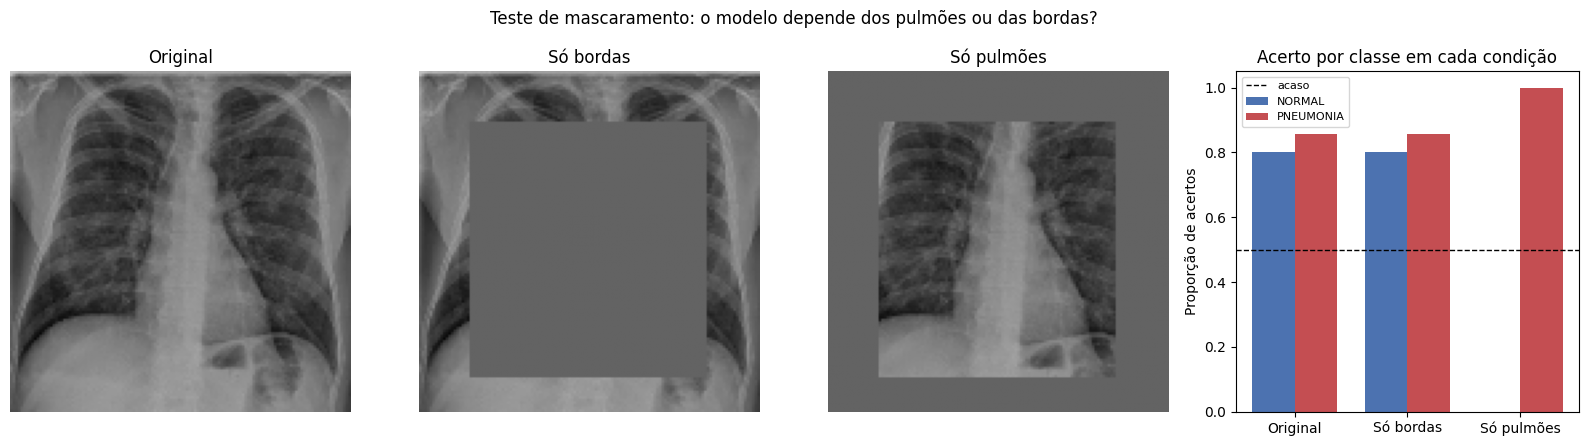

In [ ]:
# --- Imagens do teste em memória (mesma ordem de y_true) ---
x_test = np.concatenate([test_gen[i][0] for i in range(len(test_gen))])
y_true_arr = np.array(y_true)

# Região central aproximada dos pulmões, em proporção do tamanho da imagem
lin0, lin1 = int(0.15 * IMG_SIZE), int(0.90 * IMG_SIZE)
col0, col1 = int(0.15 * IMG_SIZE), int(0.85 * IMG_SIZE)

def so_bordas(imgs):
    """Cobre a região central (pulmões) com o brilho médio de cada imagem."""
    out = imgs.copy()
    for k in range(len(out)):
        out[k, lin0:lin1, col0:col1, :] = imgs[k].mean()
    return out

def so_pulmoes(imgs):
    """Mantém só a região central e cobre o resto (bordas, cantos, letras, datas)."""
    out = np.empty_like(imgs)
    for k in range(len(imgs)):
        out[k] = imgs[k].mean()
        out[k, lin0:lin1, col0:col1, :] = imgs[k, lin0:lin1, col0:col1, :]
    return out

condicoes = {
    "Original": x_test,
    "Só bordas": so_bordas(x_test),
    "Só pulmões": so_pulmoes(x_test),
}

# --- Aplicar o melhor modelo (sem retreinar) em cada condição ---
resultados_mask = []
for nome, x in condicoes.items():
    pred = (best_model.predict(x, verbose=0).ravel() >= 0.5).astype(int)
    resultados_mask.append({
        "Condição": nome,
        "Acurácia": (pred == y_true_arr).mean(),
        "Acerto em NORMAL": (pred[y_true_arr == 0] == 0).mean(),
        "Acerto em PNEUMONIA": (pred[y_true_arr == 1] == 1).mean(),
    })
df_mask = pd.DataFrame(resultados_mask)
display(df_mask.round(3))

# --- Gráfico: um exemplo de cada condição + acerto por classe ---
fig = plt.figure(figsize=(16, 4.5))
idx_ex = int(np.where(y_true_arr == 1)[0][0])   # uma imagem de PNEUMONIA como exemplo
for j, (nome, x) in enumerate(condicoes.items()):
    ax = fig.add_subplot(1, 4, j + 1)
    ax.imshow(x[idx_ex].squeeze(), cmap="gray", vmin=0, vmax=1)
    ax.set_title(nome)
    ax.axis("off")

ax = fig.add_subplot(1, 4, 4)
pos = np.arange(len(df_mask))
larg = 0.38
ax.bar(pos - larg / 2, df_mask["Acerto em NORMAL"], larg, label="NORMAL", color="#4C72B0")
ax.bar(pos + larg / 2, df_mask["Acerto em PNEUMONIA"], larg, label="PNEUMONIA", color="#C44E52")
ax.axhline(0.5, color="k", ls="--", lw=1, label="acaso")
ax.set_xticks(pos)
ax.set_xticklabels(df_mask["Condição"])
ax.set_ylim(0, 1.05)
ax.set_ylabel("Proporção de acertos")
ax.set_title("Acerto por classe em cada condição")
ax.legend(fontsize=8)

plt.suptitle("Teste de mascaramento: o modelo depende dos pulmões ou das bordas?")
plt.tight_layout()
plt.savefig("fig6_mascaramento.png", dpi=150, bbox_inches="tight")
plt.show()

### Grad-CAM: onde o modelo olha para decidir?

O Grad-CAM gera um mapa de calor que indica quais regiões da imagem mais influenciaram a decisão do modelo. Ele usa a última camada convolucional: calculo o gradiente da probabilidade da classe prevista em relação às ativações dessa camada, o que mostra quanto cada filtro contribuiu para a decisão. Depois combino os mapas de ativação ponderados por essa importância e sobreponho o resultado à imagem original.

Regiões em vermelho tiveram mais influência. Se o calor se concentrar nos pulmões, isso é compatível com o uso de informação pulmonar. Se ele cair em letras, datas, bordas ou cantos, isso reforça a hipótese de atalho. Mostro 12 imagens do teste, incluindo o único erro do modelo.

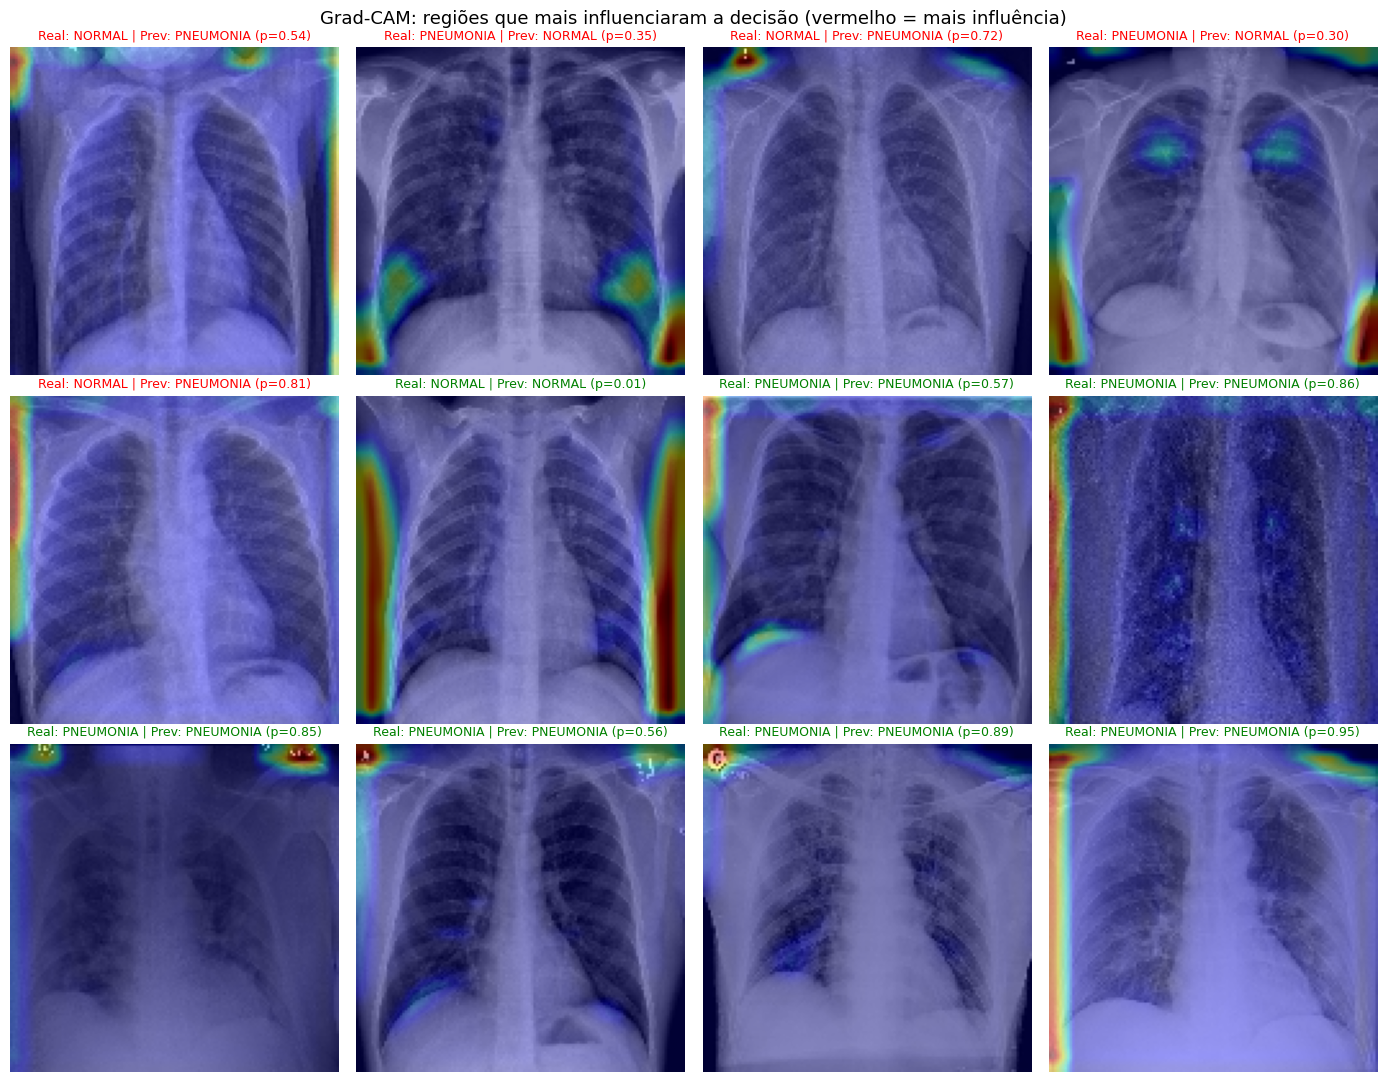

In [ ]:
# Índice da última camada convolucional do melhor modelo
idx_conv = max(i for i, camada in enumerate(best_model.layers) if isinstance(camada, Conv2D))

def grad_cam(img):
    """Mapa de calor Grad-CAM para uma imagem (128, 128, 1), em relação à classe prevista."""
    x = tf.convert_to_tensor(img[np.newaxis], dtype=tf.float32)
    with tf.GradientTape() as tape:
        h = x
        for i, camada in enumerate(best_model.layers):   # passa a imagem camada por camada
            h = camada(h, training=False)
            if i == idx_conv:
                mapas = h                                   # ativações da última conv
        p = h[0, 0]                                         # probabilidade de PNEUMONIA
        score = p if p >= 0.5 else 1 - p                    # explica a classe que o modelo escolheu
    grads = tape.gradient(score, mapas)                     # influência de cada ativação no score
    pesos = tf.reduce_mean(grads, axis=(0, 1, 2))           # importância média de cada filtro
    cam = tf.nn.relu(tf.reduce_sum(mapas[0] * pesos, axis=-1))
    cam = cam / (tf.reduce_max(cam) + 1e-8)                 # normaliza entre 0 e 1
    cam = tf.image.resize(cam[..., tf.newaxis], (IMG_SIZE, IMG_SIZE))[..., 0]
    return cam.numpy(), float(p)

# --- Escolher 12 imagens do teste: o erro + exemplos das duas classes ---
x_test = np.concatenate([test_gen[i][0] for i in range(len(test_gen))])
y_true_arr = np.array(y_true)
nomes = {v: k for k, v in test_gen.class_indices.items()}
erros = [int(i) for i in np.where(y_pred != y_true_arr)[0]]
normais = [int(i) for i in np.where(y_true_arr == 0)[0] if i not in erros][:6 - len(erros)]
pneumonias = [int(i) for i in np.where(y_true_arr == 1)[0] if i not in erros][:6]
escolhidas = erros + normais + pneumonias

fig, axes = plt.subplots(3, 4, figsize=(14, 11))
for ax, i in zip(axes.flat, escolhidas):
    cam, p = grad_cam(x_test[i])
    ax.imshow(x_test[i].squeeze(), cmap="gray")
    ax.imshow(cam, cmap="jet", alpha=0.4)              # mapa de calor por cima da radiografia
    cor = "green" if y_pred[i] == y_true_arr[i] else "red"
    ax.set_title(f"Real: {nomes[int(y_true_arr[i])]} | Prev: {nomes[int(y_pred[i])]} (p={p:.2f})",
                 fontsize=9, color=cor)
    ax.axis("off")
for ax in axes.flat[len(escolhidas):]:
    ax.axis("off")

plt.suptitle("Grad-CAM: regiões que mais influenciaram a decisão (vermelho = mais influência)", fontsize=13)
plt.tight_layout()
plt.savefig("fig7_gradcam.png", dpi=150, bbox_inches="tight")
plt.show()

## Conclusão

A melhor configuração encontrada pelo grid search, segundo o critério de menor `val_loss`, foi uma CNN com **3 blocos convolucionais (16, 32 e 64 filtros), sem dropout, batch size 8 e otimizador Adam com learning rate 0,001**.

| Conjunto | n | Loss | Acurácia |
|---|---|---|---|
| Treino | 131 | 0,203 | 0,931 |
| Validação | 28 | 0,165 | 0,964 |
| Teste | 29 | 0,151 | 0,966 |

O desempenho foi semelhante nos três conjuntos, e as curvas de aprendizado de treino e validação caem juntas, sem se afastar. Por isso, interpreto que o modelo não apresentou overfitting. No teste, ele não deixou de identificar nenhum caso de pneumonia (sensibilidade de 100%) e classificou uma imagem normal como pneumonia (especificidade de 93,3%).

Alguns padrões do grid se destacaram:
- **Adam com learning rate 0,001** esteve presente em todas as melhores configurações. Com learning rates menores, e especialmente com SGD a 0,001, várias configurações ficaram presas em `val_loss ≈ 0,69` e acurácia de 50%, o que corresponde a um modelo que não aprendeu.
- **Três blocos convolucionais** superaram dois na maioria das comparações equivalentes.
- **O dropout não teve efeito consistente**, provavelmente porque o uso de `GlobalAveragePooling2D` já mantém o modelo pequeno (cerca de 25 mil parâmetros).

### Limitações

- **Tamanho do dataset:** com 28 imagens de validação e 29 de teste, cada acerto vale cerca de 3,5 pontos percentuais. O intervalo de confiança de 95% da acurácia no teste vai de aproximadamente 83% a 99%. As melhores configurações do grid estão praticamente empatadas, e o retreino com a mesma seed gerou uma `val_loss` diferente (0,165 contra 0,126), por causa do não determinismo da GPU.
- **Possível aprendizado por atalho:** as imagens de COVID-19 foram extraídas de artigos científicos (algumas têm letras de painel e datas), e as normais parecem vir de outra fonte, possivelmente pediátrica. O modelo pode estar distinguindo a origem das imagens, e não a doença. Como o teste vem da mesma base, ele não permite descartar essa hipótese.
- **Próximos passos:** avaliar o modelo em imagens de outra fonte, usar técnicas de interpretabilidade como o Grad-CAM para verificar se a rede se concentra nos pulmões, e comparar com transfer learning a partir de uma rede pré-treinada.